Comment prédire les clients susceptibles de résilier leur abonnement téléphonique et expliquer les facteurs qui influencent chaque prédiction afin d'aider l'entreprise à améliorer sa fidélisation ?

Objectifs
- Identifier les clients à risque de résiliation.
- Comprendre les principaux facteurs associés au churn.
- Expliquer les prédictions individuelles avec SHAP.
- Proposer des actions de fidélisation pertinentes.
- Étudier les limites et les risques d'une utilisation abusive des scores.

In [5]:
import numpy as np
import pandas as pd


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
df = pd.read_csv('Churn.csv')

In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [14]:
yes_no_cols = [
    col for col in df.columns
    if set(df[col].dropna().unique()) == {"Yes", "No"}
]

# Transformer Yes en 1 et No en 0
df[yes_no_cols] = df[yes_no_cols].replace({
    "Yes": 1,
    "No": 0
})

In [15]:
print("Colonnes transformées :", yes_no_cols)
print(df[yes_no_cols].head())
print(df.dtypes)

Colonnes transformées : ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
  Partner Dependents PhoneService PaperlessBilling Churn
0       1          0            0                1     0
1       0          0            1                0     0
2       0          0            1                1     1
3       0          0            0                0     0
4       0          0            1                1     1
customerID              str
gender                  str
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling     object
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Chu

In [16]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,1,0,1,0,No phone service,DSL,No,...,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,0,0,34,1,No,DSL,Yes,...,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,0,0,2,1,No,DSL,Yes,...,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,0,0,45,0,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,0,0,2,1,No,Fiber optic,No,...,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [17]:
# Transformer la colonne gender
df["gender"] = df["gender"].map({
    "Female": 0,
    "Male": 1
})

# Vérifier le résultat
print(df["gender"].value_counts())
print(df["gender"].head())

gender
1    3555
0    3488
Name: count, dtype: int64
0    0
1    1
2    1
3    1
4    0
Name: gender, dtype: int64


In [18]:
# Transformer la colonne MultipleLines
df["MultipleLines"] = df["MultipleLines"].map({
    "No": 0,
    "No phone service": 0,
    "Yes": 1
})

# Vérifier le résultat
print(df["MultipleLines"].value_counts())
print(df["MultipleLines"].head())

MultipleLines
0    4072
1    2971
Name: count, dtype: int64
0    0
1    0
2    0
3    0
4    0
Name: MultipleLines, dtype: int64


In [19]:
df["InternetService"].unique()

<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

In [20]:
df = pd.get_dummies(
    df,
    columns=["InternetService"],
    dtype=int
)

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG       0              0       1          0       1            0   
1  5575-GNVDE       1              0       0          0      34            1   
2  3668-QPYBK       1              0       0          0       2            1   
3  7795-CFOCW       1              0       0          0      45            0   
4  9237-HQITU       0              0       0          0       2            1   

   MultipleLines OnlineSecurity OnlineBackup  ... StreamingMovies  \
0              0             No          Yes  ...              No   
1              0            Yes           No  ...              No   
2              0            Yes          Yes  ...              No   
3              0            Yes           No  ...              No   
4              0             No           No  ...              No   

         Contract PaperlessBilling              PaymentMethod MonthlyCharges  \
0  Month-to-month       

In [21]:
df["Contract"].unique()

<ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

In [22]:
df = pd.get_dummies(
    df,
    columns=["Contract"],
    dtype=int
)

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG       0              0       1          0       1            0   
1  5575-GNVDE       1              0       0          0      34            1   
2  3668-QPYBK       1              0       0          0       2            1   
3  7795-CFOCW       1              0       0          0      45            0   
4  9237-HQITU       0              0       0          0       2            1   

   MultipleLines OnlineSecurity OnlineBackup  ...              PaymentMethod  \
0              0             No          Yes  ...           Electronic check   
1              0            Yes           No  ...               Mailed check   
2              0            Yes          Yes  ...               Mailed check   
3              0            Yes           No  ...  Bank transfer (automatic)   
4              0             No           No  ...           Electronic check   

  MonthlyCharges TotalCharges Churn In

In [23]:
df = pd.get_dummies(
    df,
    columns=["PaymentMethod"],
    dtype=int
)

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG       0              0       1          0       1            0   
1  5575-GNVDE       1              0       0          0      34            1   
2  3668-QPYBK       1              0       0          0       2            1   
3  7795-CFOCW       1              0       0          0      45            0   
4  9237-HQITU       0              0       0          0       2            1   

   MultipleLines OnlineSecurity OnlineBackup  ... InternetService_DSL  \
0              0             No          Yes  ...                   1   
1              0            Yes           No  ...                   1   
2              0            Yes          Yes  ...                   1   
3              0            Yes           No  ...                   1   
4              0             No           No  ...                   0   

  InternetService_Fiber optic InternetService_No Contract_Month-to-month  \
0   

In [24]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,0,0,1,0,1,0,0,No,Yes,...,1,0,0,1,0,0,0,0,1,0
1,5575-GNVDE,1,0,0,0,34,1,0,Yes,No,...,1,0,0,0,1,0,0,0,0,1
2,3668-QPYBK,1,0,0,0,2,1,0,Yes,Yes,...,1,0,0,1,0,0,0,0,0,1
3,7795-CFOCW,1,0,0,0,45,0,0,Yes,No,...,1,0,0,0,1,0,1,0,0,0
4,9237-HQITU,0,0,0,0,2,1,0,No,No,...,0,1,0,1,0,0,0,0,1,0


In [25]:
df["OnlineBackup"].unique()

<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

In [26]:
df["OnlineSecurity"].unique()

<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

In [27]:
df["OnlineSecurity"] = df["OnlineSecurity"].map({
    "No": 0,
    "No internet service": 0,
    "Yes": 1
})

# Vérifier le résultat
print(df["OnlineSecurity"].value_counts())
print(df["OnlineSecurity"].head())

OnlineSecurity
0    5024
1    2019
Name: count, dtype: int64
0    0
1    1
2    1
3    1
4    0
Name: OnlineSecurity, dtype: int64


In [28]:
df["OnlineBackup"] = df["OnlineBackup"].map({
    "No": 0,
    "No internet service": 0,
    "Yes": 1
})

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   customerID                               7043 non-null   str    
 1   gender                                   7043 non-null   int64  
 2   SeniorCitizen                            7043 non-null   int64  
 3   Partner                                  7043 non-null   object 
 4   Dependents                               7043 non-null   object 
 5   tenure                                   7043 non-null   int64  
 6   PhoneService                             7043 non-null   object 
 7   MultipleLines                            7043 non-null   int64  
 8   OnlineSecurity                           7043 non-null   int64  
 9   OnlineBackup                             7043 non-null   int64  
 10  DeviceProtection                         7043 non-null   st

In [30]:
# Afficher les colonnes de type object ou str
cols_str = df.select_dtypes(include=["object", "str"]).columns

print(cols_str.tolist())

['customerID', 'Partner', 'Dependents', 'PhoneService', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'TotalCharges', 'Churn']


In [31]:
df["TotalCharges"].unique()



<ArrowStringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

In [32]:
df.isna().sum()

customerID                                 0
gender                                     0
SeniorCitizen                              0
Partner                                    0
Dependents                                 0
tenure                                     0
PhoneService                               0
MultipleLines                              0
OnlineSecurity                             0
OnlineBackup                               0
DeviceProtection                           0
TechSupport                                0
StreamingTV                                0
StreamingMovies                            0
PaperlessBilling                           0
MonthlyCharges                             0
TotalCharges                               0
Churn                                      0
InternetService_DSL                        0
InternetService_Fiber optic                0
InternetService_No                         0
Contract_Month-to-month                    0
Contract_O

In [33]:
df["Dependents"].unique()

array([0, 1], dtype=object)

In [34]:
df["TechSupport"].unique()

<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

In [35]:

# Modalités recherchées
target_values = {"No", "Yes", "No internet service"}

# Identifier les colonnes contenant exactement ces modalités
cols_to_encode = [
    col for col in df.select_dtypes(include=["object", "str"]).columns
    if set(df[col].dropna().unique()) == target_values
]

print("Colonnes à encoder :", cols_to_encode)

# Appliquer le One-Hot Encoding
df = pd.get_dummies(
    df,
    columns=cols_to_encode,
    dtype=int
)

print("Dimensions après encodage :", df.shape)

Colonnes à encoder : ['DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
Dimensions après encodage : (7043, 36)


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 36 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   customerID                               7043 non-null   str    
 1   gender                                   7043 non-null   int64  
 2   SeniorCitizen                            7043 non-null   int64  
 3   Partner                                  7043 non-null   object 
 4   Dependents                               7043 non-null   object 
 5   tenure                                   7043 non-null   int64  
 6   PhoneService                             7043 non-null   object 
 7   MultipleLines                            7043 non-null   int64  
 8   OnlineSecurity                           7043 non-null   int64  
 9   OnlineBackup                             7043 non-null   int64  
 10  PaperlessBilling                         7043 non-null   ob

In [37]:
cols_to_convert = df.select_dtypes(
    include=["object", "str"]
).columns


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 36 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   customerID                               7043 non-null   str    
 1   gender                                   7043 non-null   int64  
 2   SeniorCitizen                            7043 non-null   int64  
 3   Partner                                  7043 non-null   object 
 4   Dependents                               7043 non-null   object 
 5   tenure                                   7043 non-null   int64  
 6   PhoneService                             7043 non-null   object 
 7   MultipleLines                            7043 non-null   int64  
 8   OnlineSecurity                           7043 non-null   int64  
 9   OnlineBackup                             7043 non-null   int64  
 10  PaperlessBilling                         7043 non-null   ob

In [39]:
df["TotalCharges"] = df["TotalCharges"].astype(str)

print(df["TotalCharges"].dtype)

str


In [40]:
df["TotalCharges"].unique()

<ArrowStringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

In [41]:
df.isna().sum()

customerID                                 0
gender                                     0
SeniorCitizen                              0
Partner                                    0
Dependents                                 0
tenure                                     0
PhoneService                               0
MultipleLines                              0
OnlineSecurity                             0
OnlineBackup                               0
PaperlessBilling                           0
MonthlyCharges                             0
TotalCharges                               0
Churn                                      0
InternetService_DSL                        0
InternetService_Fiber optic                0
InternetService_No                         0
Contract_Month-to-month                    0
Contract_One year                          0
Contract_Two year                          0
PaymentMethod_Bank transfer (automatic)    0
PaymentMethod_Credit card (automatic)      0
PaymentMet

In [42]:
cols = df.select_dtypes(include=["object", "str"]).columns

for col in cols:
    print(f"\n{col}")
    print(df[col].unique()[:10])


customerID
<ArrowStringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU']
Length: 10, dtype: str

Partner
[1 0]

Dependents
[0 1]

PhoneService
[0 1]

PaperlessBilling
[1 0]

TotalCharges
<ArrowStringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95']
Length: 10, dtype: str

Churn
[0 1]


In [43]:
# 1. Convertir les colonnes binaires en int
binary_cols = [
    "Partner",
    "Dependents",
    "PhoneService",
    "Churn",
    "PaperlessBilling"
]

df[binary_cols] = df[binary_cols].astype(int)

# 2. Convertir TotalCharges en float
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
).astype(float)

# 4. Vérifier les types
print(df[[
    "Partner", "Dependents", "PhoneService",
    "PaperlessBilling", "TotalCharges", "Churn"
]].dtypes)

print("\nValeurs manquantes dans TotalCharges :",
      df["TotalCharges"].isna().sum())

Partner               int64
Dependents            int64
PhoneService          int64
PaperlessBilling      int64
TotalCharges        float64
Churn                 int64
dtype: object

Valeurs manquantes dans TotalCharges : 11


In [44]:
df.dropna(subset=["customerID"], inplace=True)

C:\Users\eyadh\AppData\Local\Temp\ipykernel_18612\276956557.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["customerID"], inplace=True)


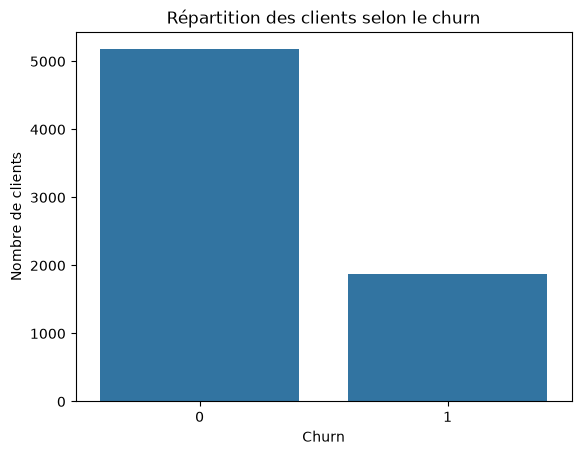

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [45]:
sns.countplot(data=df, x="Churn")
plt.title("Répartition des clients selon le churn")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")
plt.show()

print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

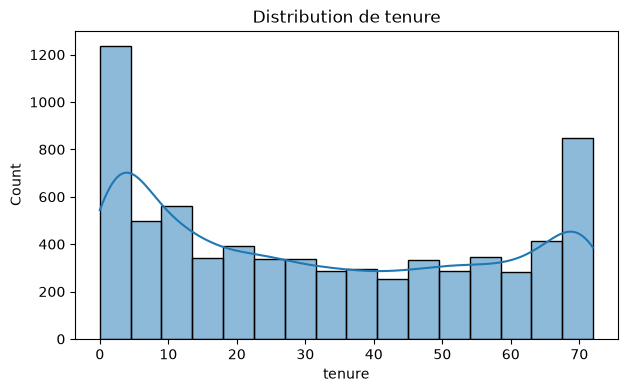

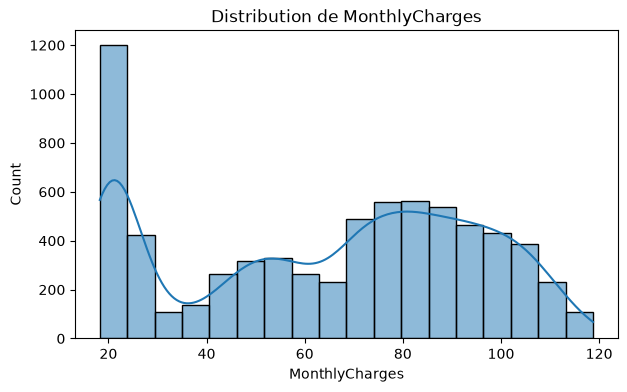

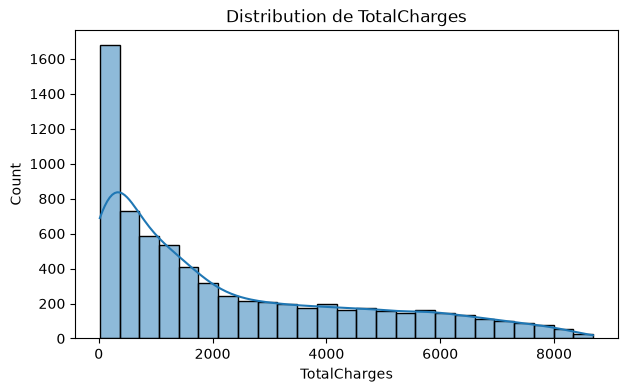

In [46]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution de {col}")
    plt.show()

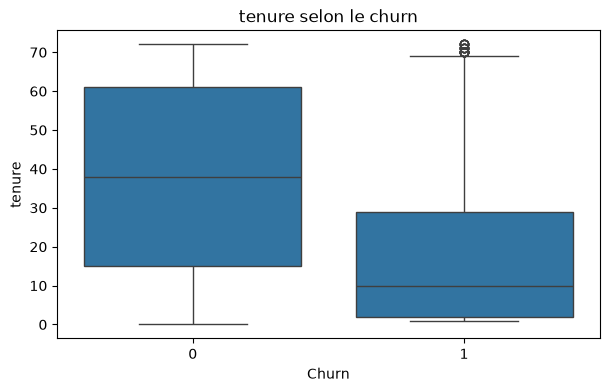

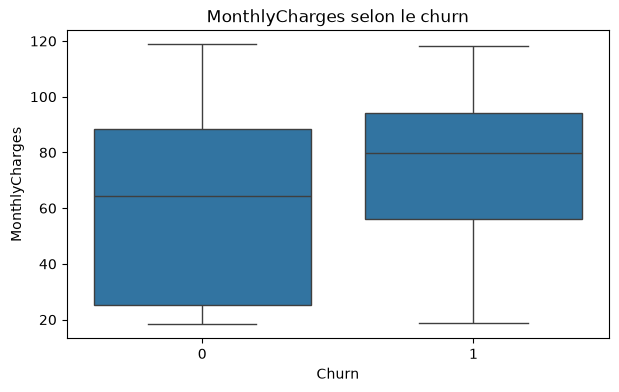

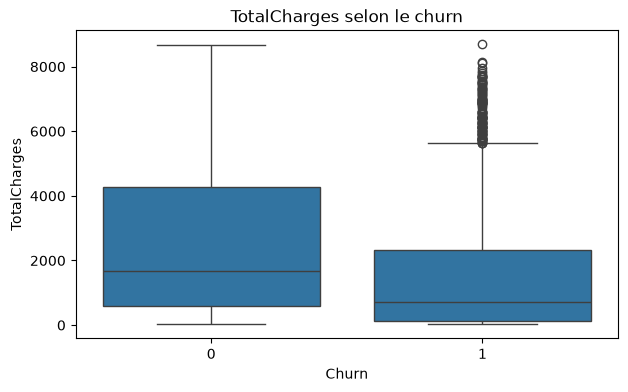

In [47]:
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Churn", y=col)
    plt.title(f"{col} selon le churn")
    plt.show()

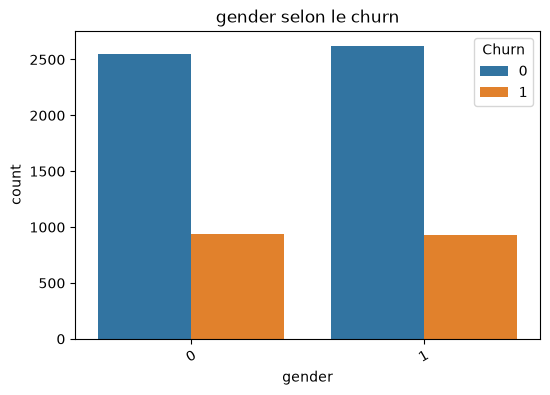

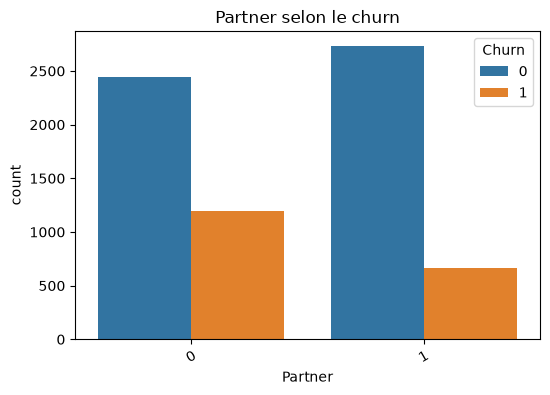

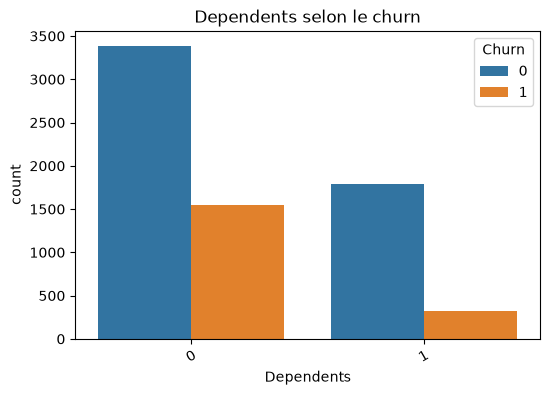

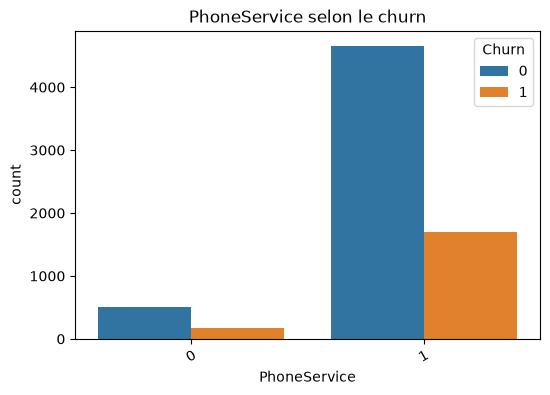

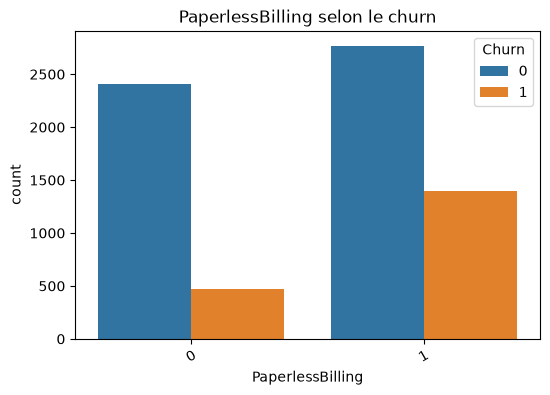

In [48]:
categorical_cols = [
    "gender", "Partner", "Dependents",
    "PhoneService", "PaperlessBilling"
]

for col in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col, hue="Churn")
    plt.title(f"{col} selon le churn")
    plt.xticks(rotation=30)
    plt.show()

In [52]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 mois",
        "13-24 mois",
        "25-48 mois",
        "49-72 mois"
    ]
)

print(df["TenureGroup"].value_counts())

TenureGroup
49-72 mois    2239
0-12 mois     2186
25-48 mois    1594
13-24 mois    1024
Name: count, dtype: int64


In [53]:
median_charges = df["MonthlyCharges"].median()

df["HighMonthlyCharges"] = (
    df["MonthlyCharges"] > median_charges
).astype(int)

print(df["HighMonthlyCharges"].value_counts())

HighMonthlyCharges
0    3528
1    3515
Name: count, dtype: int64


In [54]:
from pathlib import Path

# Créer le dossier de destination
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarder le dataset préparé
output_path = output_dir / "telco_features.csv"
df.to_csv(output_path, index=False)

print(f"Dataset sauvegardé : {output_path}")
print("Dimensions :", df.shape)

Dataset sauvegardé : data\processed\telco_features.csv
Dimensions : (7043, 38)
